Model: TownCode ~ LATITUDE
Data Split: 80% Train (5889 rows) | 20% Test (1473 rows)
Test Set Prediction Score (R²): 94.73%
Custom Prediction: When LATITUDE =   1  -->  Predicted TownCode = -1791.6271
Custom Prediction: When LATITUDE = 100  -->  Predicted TownCode = 1880.0406


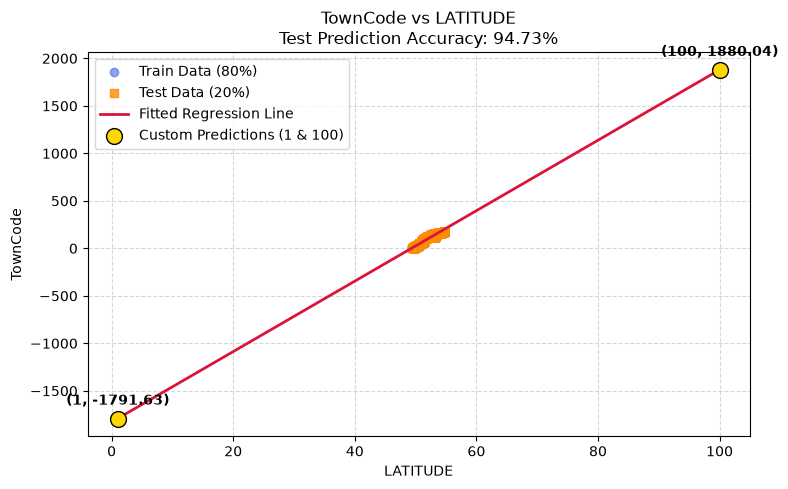

Model: Risk_Level ~ AVG_NOISE_LVL
Data Split: 80% Train (3099 rows) | 20% Test (775 rows)
Test Set Prediction Score (R²): 88.87%
Custom Prediction: When AVG_NOISE_LVL =   1  -->  Predicted Risk_Level = -4.0095
Custom Prediction: When AVG_NOISE_LVL = 100  -->  Predicted Risk_Level = 6.1547


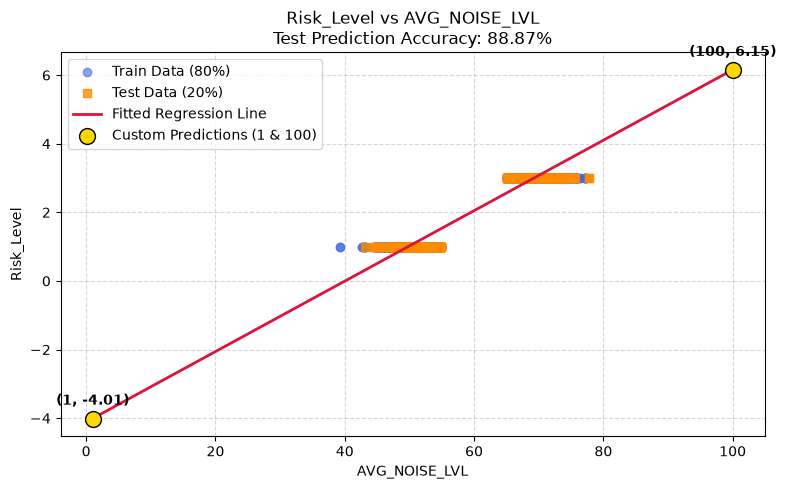

Model: Duration_hours ~ AVG_NOISE_LVL
Data Split: 80% Train (5889 rows) | 20% Test (1473 rows)
Test Set Prediction Score (R²): 1.73%
Custom Prediction: When AVG_NOISE_LVL =   1  -->  Predicted Duration_hours = 5.4652
Custom Prediction: When AVG_NOISE_LVL = 100  -->  Predicted Duration_hours = 13.4578


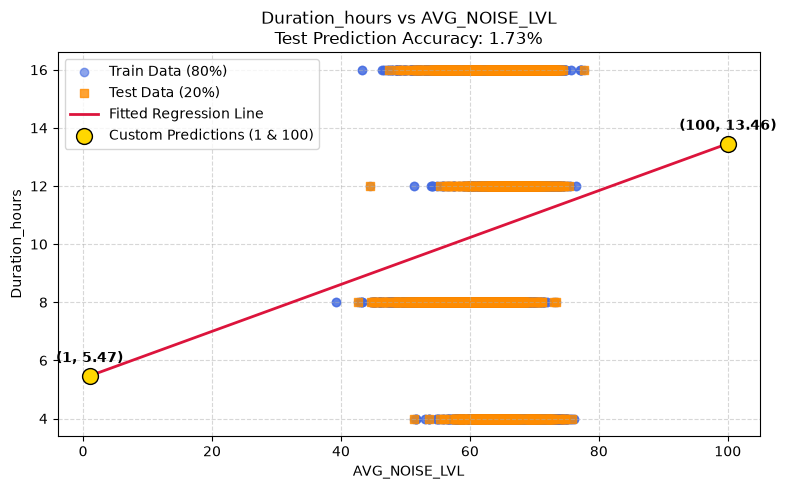

Model: Risk_Level ~ Duration_hours
Data Split: 80% Train (3099 rows) | 20% Test (775 rows)
Test Set Prediction Score (R²): 1.74%
Custom Prediction: When Duration_hours =   1  -->  Predicted Risk_Level = 2.2732
Custom Prediction: When Duration_hours = 100  -->  Predicted Risk_Level = 4.5708


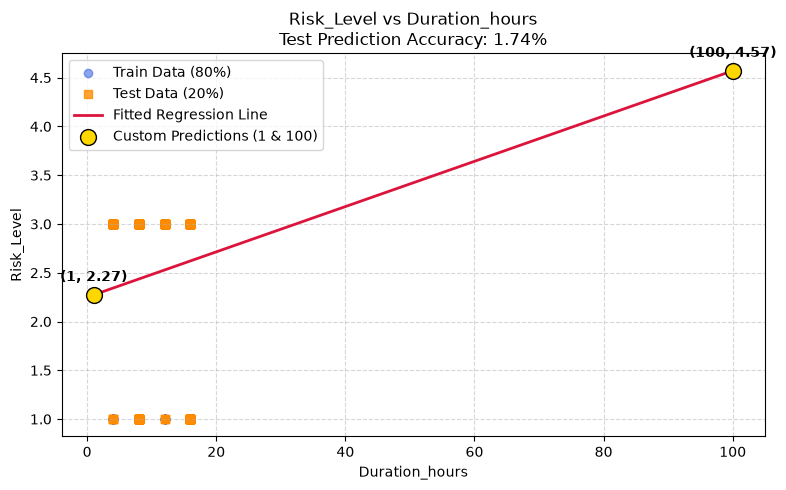

Model: Duration_hours ~ LONGITUDE
Data Split: 80% Train (5889 rows) | 20% Test (1473 rows)
Test Set Prediction Score (R²): -0.11%
Custom Prediction: When LONGITUDE =   1  -->  Predicted Duration_hours = 8.8398
Custom Prediction: When LONGITUDE = 100  -->  Predicted Duration_hours = 17.5497


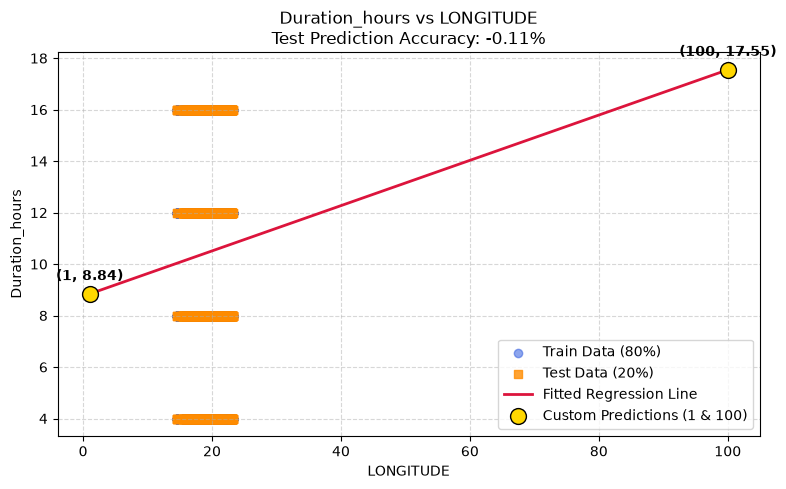

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

# ==========================================================
# Create TownCode (Latitude -> Longitude)
# ==========================================================
town_locations = (
    df.groupby("TOWN")[["LATITUDE", "LONGITUDE"]]
    .first()
    .reset_index()
)
town_locations = town_locations.sort_values(
    by=["LATITUDE", "LONGITUDE"], ascending=[True, True]
).reset_index(drop=True)
town_locations["TownCode"] = range(1, len(town_locations) + 1)

df = df.merge(town_locations[["TOWN", "TownCode"]], on="TOWN", how="left")

# ==========================================================
# Convert Risk Level to Numeric
# ==========================================================
df["Risk_Level"] = df["Risk_Level"].astype(str).str.strip().str.lower()
risk_mapping = {"low": 1, "medium": 2, "high": 3}
df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# 80/20 Train-Test Split, Single Plot & Prediction Function
# ==========================================================
def train_test_and_plot(df, x_col, y_col, custom_inputs=[1, 100], test_size=0.20, random_state=42):
    # Prepare and clean data
    data = df[[x_col, y_col]].copy()
    data[x_col] = pd.to_numeric(data[x_col], errors="coerce")
    data[y_col] = pd.to_numeric(data[y_col], errors="coerce")
    data = data.dropna()

    if len(data) < 5:
        print(f"Not enough valid data points for {y_col} ~ {x_col}")
        return

    # Split dataset: 80% Train, 20% Test
    train_data, test_data = train_test_split(
        data, test_size=test_size, random_state=random_state
    )

    # 1. Train Model on 80% Training Data
    X_train = sm.add_constant(train_data[x_col])
    Y_train = train_data[y_col]
    model = sm.OLS(Y_train, X_train).fit()

    # 2. Predict on 20% Test Data to calculate Test Accuracy
    X_test = sm.add_constant(test_data[x_col], has_constant="add")
    Y_test_pred = model.predict(X_test)
    test_r2_score = r2_score(test_data[y_col], Y_test_pred) * 100

    # 3. Predict for Custom Inputs (X = 1 and X = 100)
    custom_df = pd.DataFrame({x_col: custom_inputs})
    X_custom = sm.add_constant(custom_df, has_constant="add")
    custom_preds = model.predict(X_custom)

    print("=" * 65)
    print(f"Model: {y_col} ~ {x_col}")
    print(f"Data Split: {int((1-test_size)*100)}% Train ({len(train_data)} rows) | {int(test_size*100)}% Test ({len(test_data)} rows)")
    print(f"Test Set Prediction Score (R²): {test_r2_score:.2f}%")
    for val, pred in zip(custom_inputs, custom_preds):
        print(f"Custom Prediction: When {x_col} = {val:>3}  -->  Predicted {y_col} = {pred:.4f}")
    print("=" * 65)

    # ======================================================
    # Single Visual Plot
    # ======================================================
    plt.figure(figsize=(8, 5))

    # Plot 80% Training Points
    plt.scatter(
        train_data[x_col], train_data[y_col],
        color="royalblue", alpha=0.6, label=f"Train Data ({int((1-test_size)*100)}%)"
    )

    # Plot 20% Test Points (Actual vs Model Target)
    plt.scatter(
        test_data[x_col], test_data[y_col],
        color="darkorange", alpha=0.8, marker="s", label=f"Test Data ({int(test_size*100)}%)"
    )

    # Plot Model Regression Line
    min_x = min(data[x_col].min(), min(custom_inputs))
    max_x = max(data[x_col].max(), max(custom_inputs))
    x_line = np.linspace(min_x, max_x, 200)
    X_line_const = sm.add_constant(x_line)
    
    plt.plot(
        x_line, model.predict(X_line_const),
        color="crimson", linewidth=2, label="Fitted Regression Line"
    )

    # Highlight Custom Predictions (X=1, X=100)
    plt.scatter(
        custom_inputs, custom_preds,
        color="gold", edgecolors="black", s=130, zorder=5, label="Custom Predictions (1 & 100)"
    )

    for val, pred in zip(custom_inputs, custom_preds):
        plt.annotate(
            f"({val}, {pred:.2f})",
            (val, pred),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontweight="bold"
        )

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(f"{y_col} vs {x_col}\nTest Prediction Accuracy: {test_r2_score:.2f}%")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()

    plt.savefig(f"{y_col}_vs_{x_col}_80_20_split.png", dpi=300)
    plt.show()

# ==========================================================
# Run Models
# ==========================================================
model_pairs = [
    ("LATITUDE", "TownCode"),
    ("AVG_NOISE_LVL", "Risk_Level"),
    ("AVG_NOISE_LVL", "Duration_hours"),
    ("Duration_hours", "Risk_Level"),
    ("LONGITUDE", "Duration_hours"),
]

for x_var, y_var in model_pairs:
    train_test_and_plot(df, x_var, y_var, custom_inputs=[1, 100], test_size=0.20)